In [1]:
%pip install rdatasets


     ---------------------------------------- 0.0/44.8 kB ? eta -:--:--
     ----------------- -------------------- 20.5/44.8 kB 330.3 kB/s eta 0:00:01
     -------------------------- ----------- 30.7/44.8 kB 330.3 kB/s eta 0:00:01
     -------------------------- ----------- 30.7/44.8 kB 330.3 kB/s eta 0:00:01
     ---------------------------------- --- 41.0/44.8 kB 196.9 kB/s eta 0:00:01
     -------------------------------------- 44.8/44.8 kB 201.9 kB/s eta 0:00:00
   ---------------------------------------- 0.0/50.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/50.1 MB 640.0 kB/s eta 0:01:19
   ---------------------------------------- 0.0/50.1 MB 653.6 kB/s eta 0:01:17
   ---------------------------------------- 0.0/50.1 MB 653.6 kB/s eta 0:01:17
   ---------------------------------------- 0.1/50.1 MB 416.7 kB/s eta 0:02:00
   ---------------------------------------- 0.1/50.1 MB 514.3 kB/s eta 0:01:38
   ---------------------------------------- 0.2/50.1 MB 697.2 

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.datasets import load_wine
from rdatasets import data


# Dataset 1: Wine (for kNN)
wine_data = load_wine()  # Use a different variable name
wine_df = pd.DataFrame(data=wine_data.data, columns=wine_data.feature_names)
wine_df["target"] = wine_data.target

# Dataset 2: Chickwts (for Recommendation)
chickwts = data("chickwts").dropna()

# Dataset 3: USArrests (for PCA & Clustering)
usarrests = data("USArrests").dropna()

# Display dataset summaries
print("Wine Dataset:\n", wine_df.head(), "\n")
print("Chickwts Dataset:\n", chickwts.head(), "\n")
print("USArrests Dataset:\n", usarrests.head(), "\n")

Wine Dataset:
    alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  targe

In [ ]:
# Dataset Preparation

# 1. Remove unnecessary rownames columns
chickwts = chickwts.drop(columns=["rownames"])
usarrests = usarrests.drop(columns=["rownames"])

# 2. Inspect dataset shapes
print("Wine Dataset Shape:", wine_df.shape)
print("Chickwts Dataset Shape:", chickwts.shape)
print("USArrests Dataset Shape:", usarrests.shape)

# 3. Inspect data types
print("\nWine Dataset Information:")
wine_df.info()

print("\nChickwts Dataset Information:")
chickwts.info()

print("\nUSArrests Dataset Information:")
usarrests.info()

# 4. Check missing values
print("\nWine Missing Values:")
print(wine_df.isnull().sum())

print("\nChickwts Missing Values:")
print(chickwts.isnull().sum())

print("\nUSArrests Missing Values:")
print(usarrests.isnull().sum())

# 5. Check duplicates
print("\nWine Duplicates:", wine_df.duplicated().sum())
print("Chickwts Duplicates:", chickwts.duplicated().sum())
print("USArrests Duplicates:", usarrests.duplicated().sum())

# 6. Summary statistics
print("\nWine Summary:")
display(wine_df.describe())

print("\nChickwts Summary:")
display(chickwts.describe())

print("\nUSArrests Summary:")
display(usarrests.describe())


Wine Dataset Shape: (178, 14)
Chickwts Dataset Shape: (71, 2)
USArrests Dataset Shape: (50, 4)

Wine Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  o

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000



Chickwts Summary:


,weight
count,71.000000
mean,261.309859
std,78.073700
min,108.000000
25%,204.500000
50%,258.000000
75%,323.500000
max,423.000000



USArrests Summary:


,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


In [3]:
scaler = StandardScaler()

# Wine: standardize predictor features, excluding target
wine_features = wine_df.drop(columns=["target"])

wine_scaled = pd.DataFrame(
    scaler.fit_transform(wine_features),
    columns=wine_features.columns
)

# Chickwts: standardize weight
chickwts_scaled = pd.DataFrame(
    scaler.fit_transform(chickwts[["weight"]]),
    columns=["weight"]
)

# USArrests: standardize numerical features
usarrests_scaled = pd.DataFrame(
    scaler.fit_transform(usarrests),
    columns=usarrests.columns
)

# Display results
display(wine_scaled.head())
display(chickwts_scaled.head())
display(usarrests_scaled.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


,weight
0,-1.061762
1,-1.306854
2,-1.616444
3,-0.442583
4,-0.571578


,Murder,Assault,UrbanPop,Rape
0,1.255179,0.790787,-0.526195,-0.003451
1,0.513019,1.118060,-1.224067,2.509424
2,0.072361,1.493817,1.009122,1.053466
3,0.234708,0.233212,-1.084492,-0.186794
4,0.281093,1.275635,1.776781,2.088814


In [4]:
X = wine_df.drop(columns=["target"])
y = wine_df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Features shape: (178, 13)
Target shape: (178,)

Target classes:
target
1    71
0    59
2    48
Name: count, dtype: int64


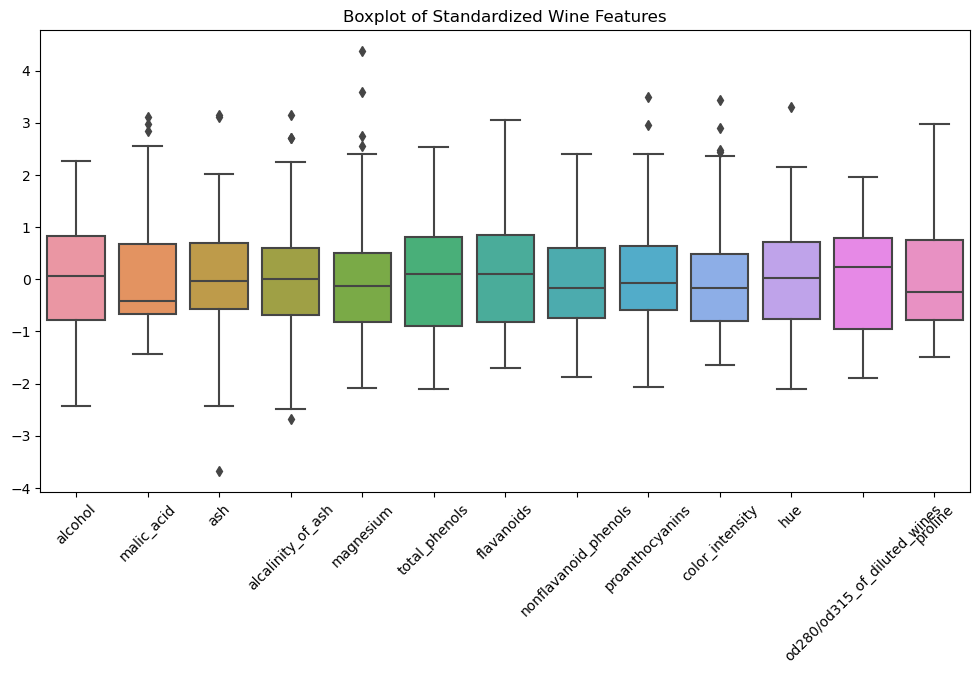

In [5]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=wine_scaled)

plt.xticks(rotation=45)
plt.title("Boxplot of Standardized Wine Features")
plt.show()

c:\Users\HomePC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


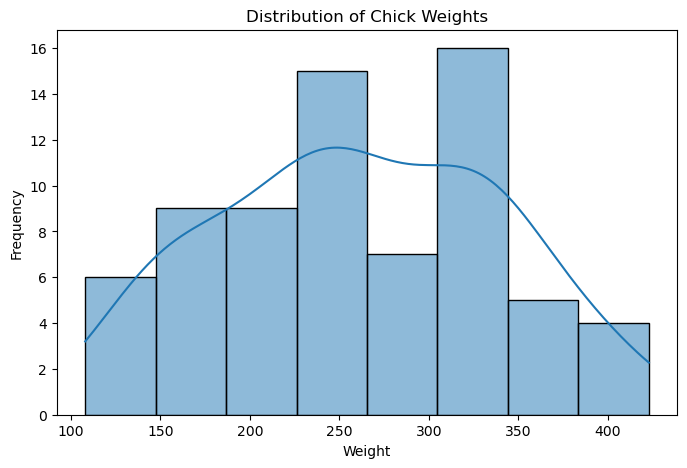

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(data=chickwts, x="weight", kde=True)

plt.title("Distribution of Chick Weights")
plt.xlabel("Weight")
plt.ylabel("Frequency")

plt.show()

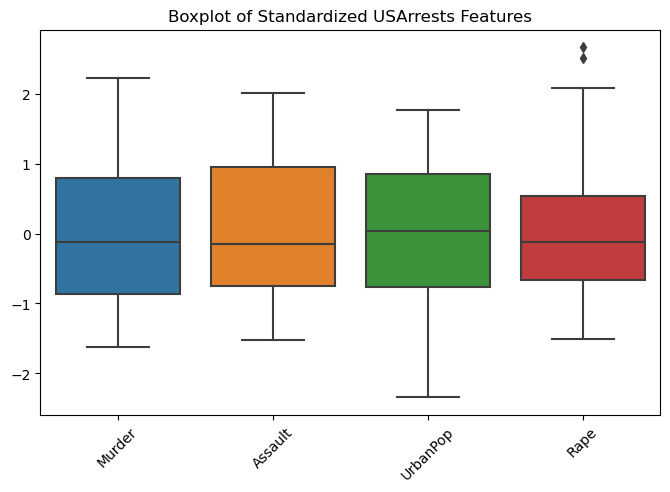

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=usarrests_scaled)

plt.title("Boxplot of Standardized USArrests Features")
plt.xticks(rotation=45)

plt.show()

In [8]:
# k-NN Classification

# 1. Separate features and target
X = wine_df.drop(columns=["target"])
y = wine_df["target"]

# 2. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Apply PCA to retain 95% variance
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Number of PCA components:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

# 5. Define hyperparameter grid
param_grid = {
    "n_neighbors": range(1, 21),
    "metric": ["euclidean", "manhattan", "minkowski"]
}

# 6. Perform GridSearchCV
grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train_pca, y_train)

print("\nBest parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

# 7. Train the best model and make predictions
best_knn = grid_search.best_estimator_

y_pred = best_knn.predict(X_test_pca)

# 8. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Number of PCA components: 10
Explained variance: 0.9624355601767975

Best parameters: {'metric': 'euclidean', 'n_neighbors': 18}
Best cross-validation accuracy: 0.9790640394088669

Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [9]:

# Feed Recommendation

# 1. Apply PCA with one component to standardized chick weights
chick_pca = PCA(n_components=1)

chick_pca_scores = chick_pca.fit_transform(chickwts_scaled)

# Add the PCA scores and feed type to a new DataFrame
chickwts_pca = chickwts.copy()

chickwts_pca["PC1"] = chick_pca_scores[:, 0]

# Display the first rows
display(chickwts_pca.head())

# Check explained variance
print(
    "Explained variance by PC1:",
    chick_pca.explained_variance_ratio_.sum()
)


,weight,feed,PC1
0,179,horsebean,-1.061762
1,160,horsebean,-1.306854
2,136,horsebean,-1.616444
3,227,horsebean,-0.442583
4,217,horsebean,-0.571578


Explained variance by PC1: 1.0


In [10]:
# 2. Create a profile for each feed type using mean and standard deviation

feed_profiles = chickwts_pca.groupby("feed")["PC1"].agg(
    ["mean", "std"]
)

display(feed_profiles)

,mean,std
feed,,
casein,0.803301,0.831169
horsebean,-1.304274,0.498257
linseed,-0.549004,0.673818
meatmeal,0.201223,0.837190
soybean,-0.191962,0.698242
sunflower,0.872099,0.629969


In [11]:
# 3. Calculate cosine similarity between feed types

feed_similarity = cosine_similarity(feed_profiles)

feed_similarity_df = pd.DataFrame(
    feed_similarity,
    index=feed_profiles.index,
    columns=feed_profiles.index
)

display(feed_similarity_df)

feed,casein,horsebean,linseed,meatmeal,soybean,sunflower
feed,,,,,,
casein,1.000000,-0.392585,0.118488,0.861557,0.509112,0.984399
horsebean,-0.392585,1.000000,0.866721,0.128671,0.591730,-0.548285
linseed,0.118488,0.866721,1.000000,0.606169,0.914961,-0.058072
meatmeal,0.861557,0.128671,0.606169,1.000000,0.875573,0.758792
soybean,0.509112,0.591730,0.914961,0.875573,1.000000,0.349728
sunflower,0.984399,-0.548285,-0.058072,0.758792,0.349728,1.000000


In [21]:
# 4. Recommend the most similar feed type

for feed in feed_similarity_df.index:
    similarities = feed_similarity_df.loc[feed].drop(feed)

    recommended_feed = similarities.idxmax()
    similarity_score = similarities.max()

    print(
        f"{feed} is most similar to {recommended_feed} "
        f"(Similarity: {similarity_score:.3f})"
    )

casein is most similar to sunflower (Similarity: 0.984)
horsebean is most similar to linseed (Similarity: 0.867)
linseed is most similar to soybean (Similarity: 0.915)
meatmeal is most similar to soybean (Similarity: 0.876)
soybean is most similar to linseed (Similarity: 0.915)
sunflower is most similar to casein (Similarity: 0.984)


In [12]:
# USArrests Clustering
# 1. Select three relevant features

usarrests_features = usarrests[["Murder", "Assault", "Rape"]]

display(usarrests_features.head())

,Murder,Assault,Rape
0,13.2,236,21.2
1,10.0,263,44.5
2,8.1,294,31.0
3,8.8,190,19.5
4,9.0,276,40.6


In [13]:
# 2. Standardize the selected features

usarrests_scaler = StandardScaler()

usarrests_scaled = usarrests_scaler.fit_transform(usarrests_features)

print("Shape of standardized data:", usarrests_scaled.shape)

Shape of standardized data: (50, 3)


In [14]:
# 3. Apply PCA with 2 components

usarrests_pca = PCA(n_components=2)

usarrests_pca_scores = usarrests_pca.fit_transform(usarrests_scaled)

print("Explained variance by 2 PCs:",
      usarrests_pca.explained_variance_ratio_.sum())

Explained variance by 2 PCs: 0.9388771782627573


c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Wi

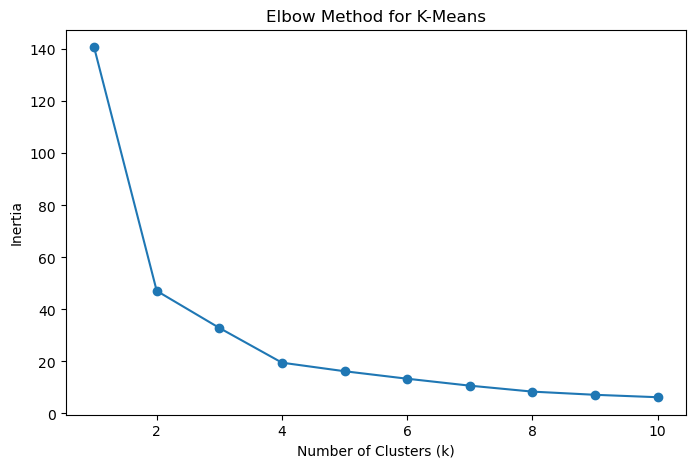

In [15]:
# 4. Find the optimal number of clusters using the Elbow Method

inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(usarrests_pca_scores)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.show()

c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Wi

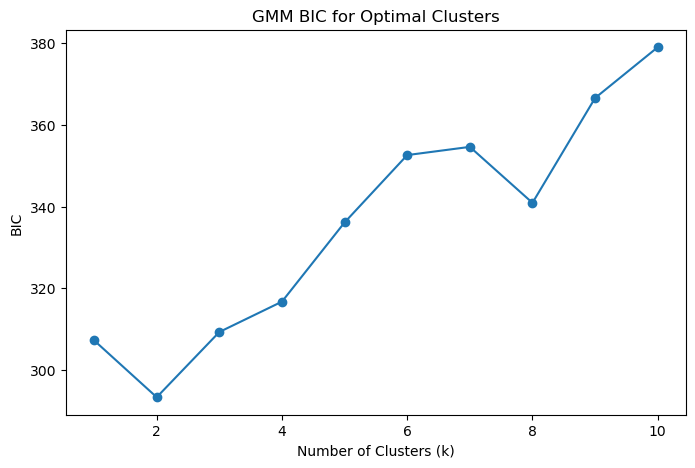

In [16]:
# 5. Find the optimal number of clusters using GMM and BIC

bic_values = []

for k in range(1, 11):
    gmm = GaussianMixture(n_components=k, random_state=42)
    gmm.fit(usarrests_pca_scores)
    bic_values.append(gmm.bic(usarrests_pca_scores))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), bic_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("BIC")
plt.title("GMM BIC for Optimal Clusters")
plt.show()

In [17]:
# 6. Fit K-Means and GMM models

# K-Means with 4 clusters
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_clusters = kmeans_model.fit_predict(usarrests_pca_scores)

# GMM with 2 clusters
gmm_model = GaussianMixture(n_components=2, random_state=42)
gmm_clusters = gmm_model.fit_predict(usarrests_pca_scores)

print("K-Means cluster counts:")
print(pd.Series(kmeans_clusters).value_counts().sort_index())

print("\nGMM cluster counts:")
print(pd.Series(gmm_clusters).value_counts().sort_index())

c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-Means cluster counts:
0    14
1    12
2    17
3     7
Name: count, dtype: int64

GMM cluster counts:
0    31
1    19
Name: count, dtype: int64


c:\Users\HomePC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


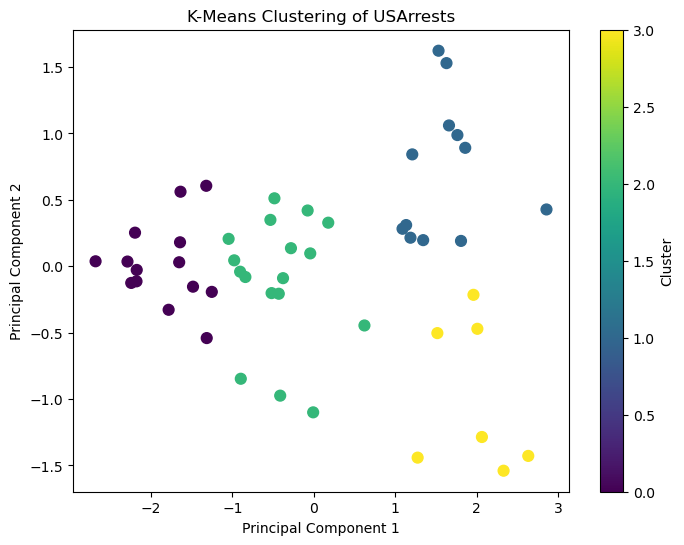

In [18]:
# 7. Visualize K-Means clusters using PCA

plt.figure(figsize=(8, 6))

plt.scatter(
    usarrests_pca_scores[:, 0],
    usarrests_pca_scores[:, 1],
    c=kmeans_clusters,
    cmap="viridis",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of USArrests")
plt.colorbar(label="Cluster")
plt.show()

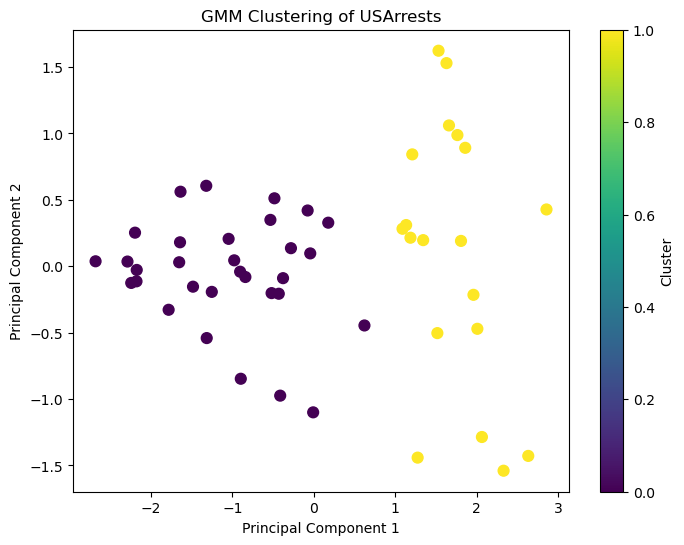

In [19]:
# 8. Visualize GMM clusters using PCA

plt.figure(figsize=(8, 6))

plt.scatter(
    usarrests_pca_scores[:, 0],
    usarrests_pca_scores[:, 1],
    c=gmm_clusters,
    cmap="viridis",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("GMM Clustering of USArrests")
plt.colorbar(label="Cluster")
plt.show()

In [20]:
# 9. Compare the average crime rates within each cluster

clustered_usarrests = usarrests_features.copy()

clustered_usarrests["KMeans_Cluster"] = kmeans_clusters
clustered_usarrests["GMM_Cluster"] = gmm_clusters

print("Average crime rates by K-Means cluster:")
display(
    clustered_usarrests.groupby("KMeans_Cluster")[
        ["Murder", "Assault", "Rape"]
    ].mean().round(2)
)

print("Average crime rates by GMM cluster:")
display(
    clustered_usarrests.groupby("GMM_Cluster")[
        ["Murder", "Assault", "Rape"]
    ].mean().round(2)
)

Average crime rates by K-Means cluster:


,Murder,Assault,Rape
KMeans_Cluster,,,
0,3.08,80.93,11.80
1,13.63,258.17,23.92
2,6.59,145.76,20.08
3,10.10,261.29,38.29


Average crime rates by GMM cluster:


,Murder,Assault,Rape
GMM_Cluster,,,
0,5.00,116.48,16.34
1,12.33,259.32,29.22


### USArrests Clustering Conclusion

The USArrests dataset was analyzed using K-Means and Gaussian Mixture Model (GMM) clustering. Murder, Assault, and Rape were selected as relevant features and standardized before applying PCA. The two principal components explained approximately 93.89% of the total variance.

The K-Means Elbow Method suggested four clusters, while the GMM BIC method selected two clusters. The K-Means model provided a more detailed grouping of states, whereas GMM produced two broader groups.

The cluster averages showed differences in crime patterns. K-Means Cluster 0 had the lowest average crime rates, while Cluster 3 had the highest average Rape rate. GMM Cluster 0 represented relatively lower crime rates, and GMM Cluster 1 represented relatively higher crime rates.

Overall, both clustering methods identified patterns in the USArrests data. GMM provided a simpler grouping, while K-Means offered more detailed segmentation. These findings help demonstrate how unsupervised learning can be used to explore crime-rate patterns across states.

### Chickwts Feed Recommendation Interpretation

The cosine similarity analysis identified the most similar feed types based on their weight profiles. Casein and sunflower showed the highest similarity score of 0.984, suggesting that their weight patterns were very similar. Linseed and soybean also showed a high similarity score of 0.915. Horsebean was most similar to linseed, while meatmeal was most similar to soybean.

The analysis demonstrates how PCA and cosine similarity can be used to compare feed types and identify similar weight patterns. These recommendations are based on similarity in the dataset and do not necessarily imply equivalent nutritional or biological effects.

### Wine k-NN Classification Interpretation

The k-NN classification model performed well on the Wine dataset. PCA retained approximately 96.24% of the variance using 10 principal components. GridSearchCV identified 18 as the optimal number of neighbors and Euclidean distance as the best distance metric.

The model achieved a cross-validation accuracy of 97.91% and a test accuracy of 100%, correctly classifying all 36 test observations. The classification report also showed strong precision, recall, and F1-scores across the classes.

These results suggest that the model can effectively classify wine samples based on the selected features. However, because the test set contains only 36 observations, further testing on a larger independent dataset would help confirm its ability to generalize to unseen data.

## Overall Conclusion

This project applied data preparation, dimensionality reduction, classification, recommendation, and clustering techniques to three datasets.

The Wine k-NN model achieved a test accuracy of 100% and a cross-validation accuracy of 97.91%, indicating strong classification performance. The Chickwts feed recommendation analysis used PCA and cosine similarity to identify feed types with similar weight profiles. The USArrests analysis applied K-Means and GMM clustering to identify different crime-rate patterns among states.

The results demonstrate the usefulness of machine learning techniques for classification, similarity-based recommendations, and exploratory clustering. However, the findings should be interpreted within the limitations of the datasets and methods used.